# E4 Weighted Voting: Acoustic and Frozen Whisper Models

Does averaging model scores improve the validation-selected single branch?

This run uses the existing 2,000 audio clips. Label 1 is MNSC / Singapore.
Label 0 is Common Voice / non-Singapore. Corpus and class are linked.
High scores do not establish accent recognition under new recording conditions.

All six matched notebooks use one saved clip list and one speaker split.
Training and validation select settings. Test speakers measure the fixed model.
The first grouped fold supplies test data. This is **one split**, not full cross-validation.

Shared implementation: [experiment_common.py](experiment_common.py).
Read its audio and evaluation functions to inspect the full procedure.
The original notebooks were backed up before this update.

## 1. Use the local audio environment

Use the **Singlish audio review (Python 3.12)** kernel.
Dependencies are already installed. This notebook does not upgrade packages.
Set the two paths below if the project moves.

In [1]:
from pathlib import Path
import sys

USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Singlish')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'audio'
else:
    PROJECT_ROOT = Path('/home/mh/nusproj/singlish-whisper')
    DATA_ROOT = PROJECT_ROOT / 'data' / 'e1_audio_1000x2' / 'data'

sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import experiment_common as common
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

%matplotlib inline
config = common.configure(PROJECT_ROOT, DATA_ROOT)
print('Audio:', DATA_ROOT)
print('Results:', config['output'])
print(json.dumps(common.environment(), indent=2))

Audio: /home/mh/nusproj/singlish-whisper/data/e1_audio_1000x2/data
Results: /home/mh/nusproj/singlish-whisper/outputs/matched_2000_seed42
{
  "python": "3.12.13",
  "packages": {
    "numpy": "2.5.1",
    "scipy": "1.18.0",
    "scikit-learn": "1.9.0",
    "librosa": "1.0.0",
    "torch": "2.13.0+cu126",
    "transformers": "4.57.6",
    "nbclient": "0.11.0"
  }
}


## 2. Verify clips and load the shared split

File hashes detect duplicate audio. Extraction failures stop the run.
No notebook silently drops clips or creates a different test set.
Each speaker stays in one partition. The split is approximately 64% / 16% / 20%.
The saved split remains fixed on later runs.

In [2]:
frame, fingerprint = common.prepare_manifest(config)
split = common.shared_split(config, frame, fingerprint)
y = frame.label.to_numpy()
groups = frame.group.to_numpy(dtype=str)
train_idx, val_idx, test_idx = (split[name] for name in ['train', 'validation', 'test'])
trainval_idx = np.sort(np.r_[train_idx, val_idx])
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(groups[val_idx]).isdisjoint(groups[test_idx])

Clips: {0: 1000, 1: 1000}
Speakers: {0: 300, 1: 583}
Dataset SHA256: 872f8ffa700bb810105b9796d6c0032c6d8c07bd9b3ffedfb6239a179d6fa8cb
{
  "train": {
    "clips": 1280,
    "speakers": 566,
    "label_counts": {
      "0": 640,
      "1": 640
    }
  },
  "validation": {
    "clips": 320,
    "speakers": 141,
    "label_counts": {
      "0": 160,
      "1": 160
    }
  },
  "test": {
    "clips": 400,
    "speakers": 176,
    "label_counts": {
      "0": 200,
      "1": 200
    }
  }
}
Speaker overlap: 0. This is one fixed grouped split, not five-fold evaluation.


## 3. Load shared features and validation-selected settings

Run the three E1 notebooks and E2 first. Only their validation choices are read here.
Their saved test scores do not select a model, weight, or threshold.
Refit every candidate on training speakers for this validation stage.

In [3]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedGroupKFold

A, W = common.load_features(config, frame, fingerprint, whisper=True)
names = ['e1_svm', 'e1_random_forest', 'e1_logistic_regression', 'e2_whisper']
templates = {}
for name in names:
    path = config['output'] / name / 'model.joblib'
    if not path.is_file():
        raise FileNotFoundError(f'Run the matching notebook first: {path}')
    templates[name] = clone(joblib.load(path))

def fit_branch(name, idx):
    matrix = W if name == 'e2_whisper' else A
    estimator = clone(templates[name])
    if name == 'e1_svm':
        # The full scaler+SVM pipeline is refitted inside each calibration fold.
        folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=common.SEED+2)
                     .split(matrix[idx], y[idx], groups[idx]))
        for left, right in folds:
            assert set(groups[idx[left]]).isdisjoint(groups[idx[right]])
        estimator = CalibratedClassifierCV(estimator=estimator, method='sigmoid', cv=folds,
                                          ensemble=False, n_jobs=1)
    return estimator.fit(matrix[idx], y[idx])

def probability(model, matrix):
    return model.predict_proba(matrix)[:, list(model.classes_).index(1)]

Acoustic features: (2000, 39)
Whisper features: (2000, 512)


## 4. Choose the acoustic branch on validation speakers

SVM calibration uses three speaker-separated folds inside training.
The scaler is fitted inside those folds. Test speakers do not enter calibration.
Random Forest and logistic-regression scores are not assumed to be perfectly calibrated.
The voting decision rule is class-1 score greater than or equal to 0.5.

In [4]:
validation_models, acoustic_rows = {}, []
for name in names:
    validation_models[name] = fit_branch(name, train_idx)
    if name != 'e2_whisper':
        p = probability(validation_models[name], A[val_idx])
        acoustic_rows.append({'name':name, **common.selection_metrics(y[val_idx], (p>=.5).astype(int))})
best_e1 = max(acoustic_rows, key=lambda row:(row['macro_f1'],row['balanced_accuracy']))['name']
print(pd.DataFrame(acoustic_rows).to_string(index=False))
print('Validation-selected acoustic branch:',best_e1)
p_acoustic_val = probability(validation_models[best_e1],A[val_idx])
p_whisper_val = probability(validation_models['e2_whisper'],W[val_idx])

/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probab

                  name  macro_f1  balanced_accuracy
                e1_svm  0.956223           0.956250
      e1_random_forest  0.931250           0.931250
e1_logistic_regression  0.928124           0.928125
Validation-selected acoustic branch: e1_svm


## 5. Choose the voting weight using validation only

The acoustic weight runs from 0 to 1 in steps of 0.1.
Endpoints represent the single branches. The threshold stays at 0.5.
Macro F1 selects the weight. Balanced accuracy breaks ties. Further ties favour 0.5.

In [5]:
weight_rows = []
for weight in np.linspace(0,1,11):
    p = weight*p_acoustic_val+(1-weight)*p_whisper_val
    weight_rows.append({'weight_acoustic':float(weight),
                       **common.selection_metrics(y[val_idx],(p>=.5).astype(int))})
selected = max(weight_rows,key=lambda row:(row['macro_f1'],row['balanced_accuracy'],
                                           -abs(row['weight_acoustic']-.5)))
weight = selected['weight_acoustic']
validation = {'acoustic_candidates':acoustic_rows,'selected_acoustic':best_e1,
              'weight_trials':weight_rows,'selected_weight':selected}
common.write_json(config['output'] / 'weighted_vote' / 'validation_selection.json',validation)
print(pd.DataFrame(weight_rows).to_string(index=False))
print('Selected acoustic weight:',weight)

 weight_acoustic  macro_f1  balanced_accuracy
             0.0  0.962499           0.962500
             0.1  0.971875           0.971875
             0.2  0.975000           0.975000
             0.3  0.978125           0.978125
             0.4  0.984375           0.984375
             0.5  0.984375           0.984375
             0.6  0.981250           0.981250
             0.7  0.971875           0.971875
             0.8  0.965622           0.965625
             0.9  0.956235           0.956250
             1.0  0.956223           0.956250
Selected acoustic weight: 0.5


## 6. Refit both branches, then evaluate test speakers

The branch and weight are fixed. Refit both branches on training plus validation.
For SVM, recreate speaker-separated calibration folds within that fitting set.
Evaluate the two branches and their vote on identical test clips.

/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/mh/miniconda3/envs/audioenv/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probab

{
  "accuracy": 0.955,
  "macro_f1": 0.9549819927971188,
  "balanced_accuracy": 0.9550000000000001,
  "roc_auc": 0.989525,
  "errors": 18,
  "confusion_matrix": [
    [
      187,
      13
    ],
    [
      5,
      195
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.03385136925266809,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.9232687389337005,
      0.979381443298969
    ],
    "balanced_accuracy": [
      0.9236043654058359,
      0.9793803059242925
    ],
    "macro_f1": [
      0.9230182456467906,
      0.9793727700454673
    ]
  }
}


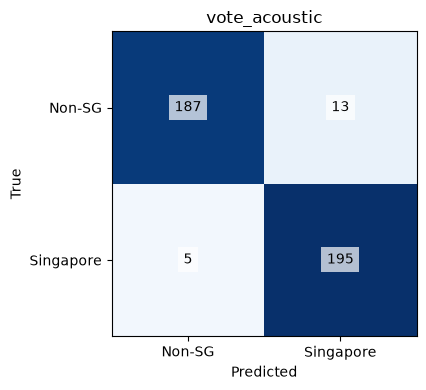

{
  "accuracy": 0.9825,
  "macro_f1": 0.9824998906243163,
  "balanced_accuracy": 0.9824999999999999,
  "roc_auc": 0.99785,
  "errors": 7,
  "confusion_matrix": [
    [
      196,
      4
    ],
    [
      3,
      197
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.01893358863890171,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.9659077050997783,
      0.9950983388465411
    ],
    "balanced_accuracy": [
      0.9658701939940278,
      0.9950985905681276
    ],
    "macro_f1": [
      0.9658526834491921,
      0.9950764856142932
    ]
  }
}


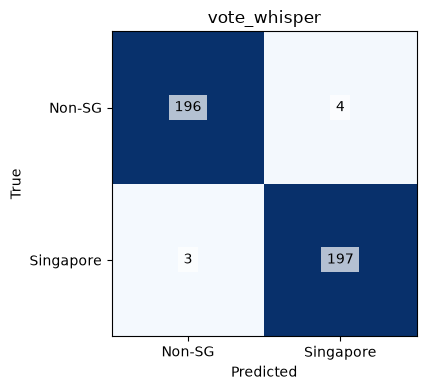

{
  "accuracy": 0.98,
  "macro_f1": 0.9799919967987194,
  "balanced_accuracy": 0.98,
  "roc_auc": 0.9994999999999999,
  "errors": 8,
  "confusion_matrix": [
    [
      192,
      8
    ],
    [
      0,
      200
    ]
  ],
  "confusion_matrix_labels": [
    0,
    1
  ],
  "brier_score": 0.01768170407260961,
  "speaker_bootstrap_ci95": {
    "accuracy": [
      0.9560702981368814,
      0.9974811083123426
    ],
    "balanced_accuracy": [
      0.9554949241698006,
      0.9974496237889096
    ],
    "macro_f1": [
      0.9559877769552272,
      0.997474729791252
    ]
  }
}


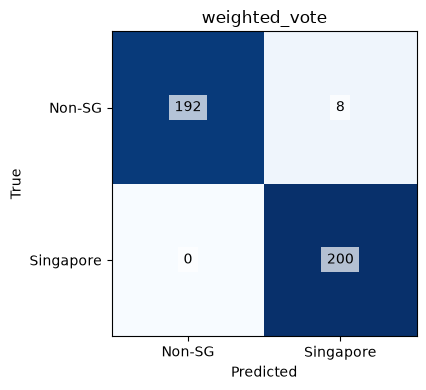

{
  "Acoustic branch": {
    "macro_f1": {
      "difference": 0.025010004001600583,
      "ci95": [
        0.010050184617212346,
        0.0419514197878572
      ]
    },
    "balanced_accuracy": {
      "difference": 0.02499999999999991,
      "ci95": [
        0.009998470540574688,
        0.04155197375360179
      ]
    }
  },
  "Whisper branch": {
    "macro_f1": {
      "difference": -0.0025078938255969074,
      "ci95": [
        -0.023810260774830165,
        0.018022194321381305
      ]
    },
    "balanced_accuracy": {
      "difference": -0.0024999999999999467,
      "ci95": [
        -0.02367104649450113,
        0.018055938220581397
      ]
    }
  }
}


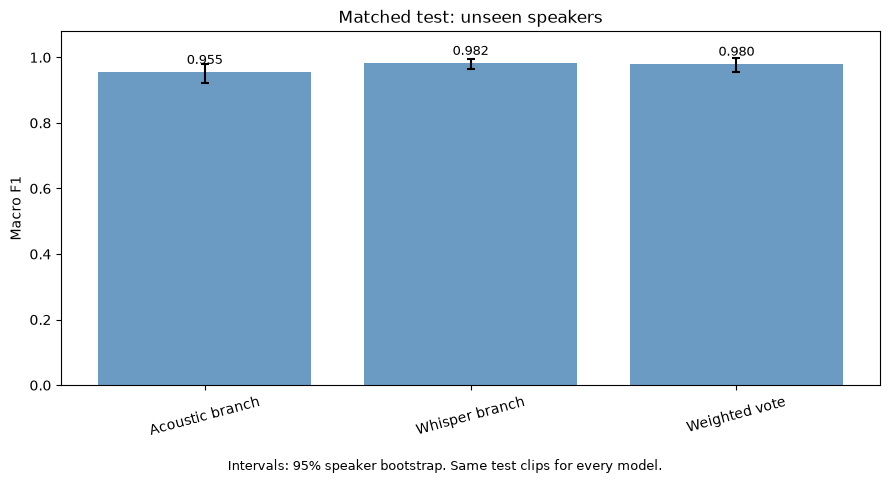

In [6]:
acoustic_model = fit_branch(best_e1,trainval_idx)
whisper_model = fit_branch('e2_whisper',trainval_idx)
p_acoustic = probability(acoustic_model,A[test_idx])
p_whisper = probability(whisper_model,W[test_idx])
p_vote = weight*p_acoustic+(1-weight)*p_whisper
probabilities = {'Acoustic branch':p_acoustic,'Whisper branch':p_whisper,'Weighted vote':p_vote}
reports = {}
for name,p in probabilities.items():
    output = {'Acoustic branch':'vote_acoustic','Whisper branch':'vote_whisper','Weighted vote':'weighted_vote'}[name]
    reports[name] = common.save_result(config,output,frame,fingerprint,split,None,
        (p>=.5).astype(int),p,validation,probability=True,
        extra={'selected_acoustic':best_e1,'weight_acoustic':weight,'threshold':.5,
               'svm_calibration':'sigmoid with three speaker-separated folds inside fitting data'})
joblib.dump({'acoustic_model':acoustic_model,'whisper_head':whisper_model,'encoder':common.MODEL_NAME,
             'weight_acoustic':weight,'threshold':.5},config['output']/'weighted_vote'/'models.joblib')
paired = {name:common.paired_intervals(y[test_idx],(p_vote>=.5).astype(int),
           (p>=.5).astype(int),groups[test_idx]) for name,p in probabilities.items() if name!='Weighted vote'}
common.write_json(config['output']/'weighted_vote'/'paired_differences.json',paired)
print(json.dumps(paired,indent=2))
common.comparison_chart(reports,config['output']/'weighted_vote'/'voting_comparison.png')

## Interpretation

If an endpoint wins, validation favours a single branch. Do not claim a voting gain.
Compare voting with both branches. Report error counts and paired uncertainty.
Keep source confounding separate from model-comparison evidence.
This run does not establish performance on new microphones or recording sources.

## Recorded result: 28 October 2026

Accuracy: **98.00%**. Macro F1: **0.9800**.
There were **8 errors among 400 test clips** from 176 speakers.
Non-Singapore clips predicted as Singapore: **8**.
Singapore clips predicted as non-Singapore: **0**.
The 95% speaker-bootstrap interval for macro F1 is **[0.9560, 0.9975]**.

Validation selected **e1_svm**, with acoustic weight **0.5**.
Validation favoured blending. The test result did not confirm an improvement over Whisper.
The vote made eight test errors. Whisper made seven.
Vote minus Whisper: macro F1 **-0.0025**.
The paired 95% interval is **[-0.0238, +0.0180]**.
The interval includes zero. Do not claim that voting improves the stronger branch.

Class and corpus remain linked. These scores do not isolate accent from recording-source effects.
Artifacts: `../outputs/matched_2000_seed42/weighted_vote/`.